# Лекция 7. «Что было бы, если бы: причинность на наблюдательных данных»

В L04–L06 мы рассмотрели модели, оценивающие вероятность дефолта в зависимости от набллюдаемых или полученных без учителя признаков. Доля брокерских депозитов ассоциировалась с повышенным риском. В логите L04 шансы банкротства росли примерно в 1.3 раза на одно стандартное отклонение этой доли, а в L05 мы находтку затвердили монотонным ограничением.

Но обычно регулятор (или, например, босс) спрашивает о другом: если ограничить брокерские депозиты каким-то потолком, банкротств станет меньше? При помощи прогноза на подобный вопрос ответить мы не можем (вспоминаем про каузальность vs корреляцию). Модель видит, что банки с брокерскими депозитами дефолтят чаще, но не знает почему. Возможно, виноваты сами депозиты. А может ими пользуются банки, которые имеют a priori более выраженный риск-профиль. 

Сегодня разберём, как оценить эффект вмешательства (average treatment effect, ATT) по наблюдательным данным, без эксперимента (классический RCT или АБ). Все методы лекции строят одно и то же — **контрфактуал** (counterfactual), то есть что было бы с теми же банками без вмешательства. Различаются они - методы - тем, как этот контрфактуал генерируют и что лежит в основе ожиданий от о переменных, которых мы не видим.

план:

1. Контрфактуал и скрытые переменные.
2. Сопоставление по склонности (PSM): у каждого банка ищем похожих двойников. Брокерские депозиты и банкротства 2008–2012 годов.
3. Разность разностей (DiD): сравниваем изменения, а не уровни. Рост ставок в 2022 году и капитал банков.
4. Синтетический контроль (SC): двойника собираем из смеси штатов. Ураган «Катрина» и депозиты.
5. Методы складываются: PSM + DiD на той же «Катрине».

Клетки с заголовком «Рисунок: …» только рисуют, в их код можно не вникать. В Colab их код свёрнут, раскрыть его можно двойным щелчком.

## 0. Подготовка

Установочная клетка почти та же, что в L06. Новые инструменты: `NearestNeighbors` (поиск ближайших соседей из L01 без регрессии) и `minimize` (численная минимизация, понадобится в §4).

In [1]:
# Библиотеки для расчётов и графиков
import numpy as np                                   # массивы и математика
import pandas as pd                                  # таблицы
import matplotlib.pyplot as plt                      # графики
import seaborn as sns                                # оформление графиков
import statsmodels.formula.api as smf                # регрессии по формуле "y ~ x"
from scipy.optimize import minimize                  # численная минимизация (§4)
from sklearn.linear_model import LogisticRegression  # логит из L04
from sklearn.neighbors import NearestNeighbors       # ближайшие соседи из L01

# Откуда берём данные: файлы лежат в репозитории курса, читаем их прямо по ссылке
DATA = "https://raw.githubusercontent.com/nvvoitov/da_intro/main/data/"

# Фиксируем случайность (сид): одно и то же число -> одинаковый результат при перезапуске
SEED = 20260101

# Косметика: параметры для отображения графиков. Вникать не обязательно
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)             # размер картинки по умолчанию
pd.set_option("display.max_columns", 30)            # показывать до 30 колонок таблицы

# Цвета лекции: с вмешательством — оранжевый, без него — синий
TREATED_COLOR = "#eb6834"
CONTROL_COLOR = "#2a78d6"
HIDDEN_COLOR = "#d03b3b"                            # скрытое и контрфактуальное

In [2]:
# Панель FDIC и список банкротств — те же файлы, что во всех лекциях
panel = pd.read_parquet(DATA + "banks_panel.parquet")
failures = pd.read_parquet(DATA + "failures.parquet")
print("строк в панели:", len(panel), "| банков:", panel["cert"].nunique())

строк в панели: 152152 | банков: 2586


## 1. Контрфактуал и скрытые переменные

Представим, что у каждого банка два возможных исхода. Это **потенциальные исходы** (potential outcomes): $Y(1)$ — обанкротился бы банк с брокерскими депозитами, $Y(0)$ — без них. Эффект для банка — разность $Y(1) - Y(0)$. Но каждый банк живёт только в одном из двух миров. Банк с брокерскими депозитами показывает нам $Y(1)$, а его $Y(0)$ остаётся неизвестным. Эта недостающая клетка и есть контрфактуал.

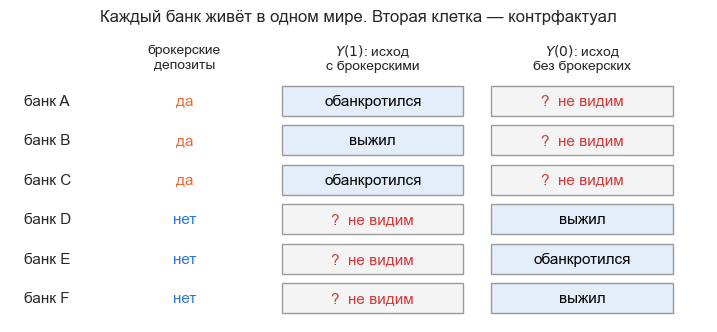

In [3]:
# @title Рисунок: два мира одного банка
names = ["банк A", "банк B", "банк C", "банк D", "банк E", "банк F"]
has_brokered = [True, True, True, False, False, False]
with_brokered = ["обанкротился", "выжил", "обанкротился", "?", "?", "?"]       # Y(1)
without_brokered = ["?", "?", "?", "выжил", "обанкротился", "выжил"]           # Y(0)

fig, ax = plt.subplots(figsize=(9, 3.8))
for i in range(len(names)):
    y = len(names) - i
    ax.text(0.02, y, names[i], va="center", fontsize=11)
    ax.text(0.25, y, "да" if has_brokered[i] else "нет", va="center", ha="center", fontsize=11,
            color=TREATED_COLOR if has_brokered[i] else CONTROL_COLOR)
    for x, value in [(0.52, with_brokered[i]), (0.82, without_brokered[i])]:
        seen = value != "?"
        ax.add_patch(plt.Rectangle((x - 0.13, y - 0.38), 0.26, 0.76, facecolor="#e3eefa" if seen else "#f4f4f4",
                                   edgecolor="#9a9a9a"))
        ax.text(x, y, value if seen else "?  не видим", va="center", ha="center", fontsize=11,
                color="black" if seen else HIDDEN_COLOR)
ax.text(0.25, 7.1, "брокерские\nдепозиты", ha="center", va="center", fontsize=10)
ax.text(0.52, 7.1, "$Y(1)$: исход\nс брокерскими", ha="center", va="center", fontsize=10)
ax.text(0.82, 7.1, "$Y(0)$: исход\nбез брокерских", ha="center", va="center", fontsize=10)
ax.set_xlim(0, 1)
ax.set_ylim(0.4, 7.8)
ax.axis("off")
ax.set_title("Каждый банк живёт в одном мире. Вторая клетка — контрфактуал", fontsize=12)
plt.show()

Эффект для одного банка узнать нельзя, зато можно оценить средний эффект по группе. Нас интересует средний эффект для тех банков, которые принимали брокерские депозиты: ATT (average treatment effect on the treated). Обозначим $T = 1$, если банк пользовался брокерскими депозитами. Наивная разница долей банкротств раскладывается на две части:

$$
\underbrace{E[Y \mid T{=}1] - E[Y \mid T{=}0]}_{\text{наивная разница}}
= \underbrace{E[Y(1) - Y(0) \mid T{=}1]}_{\text{эффект, ATT}}
+ \underbrace{E[Y(0) \mid T{=}1] - E[Y(0) \mid T{=}0]}_{\text{смещение отбора}}.
$$

**Смещение отбора** (selection bias) показывает, насколько банки с брокерскими депозитами разорялись бы чаще остальных, даже если бы этих депозитов у них не было. Каждый метод данной лекции (а их два) — способ избавиться от этого слагаемого. Откуда оно берётся, видно на схемах, где стрелка означает «влияет».

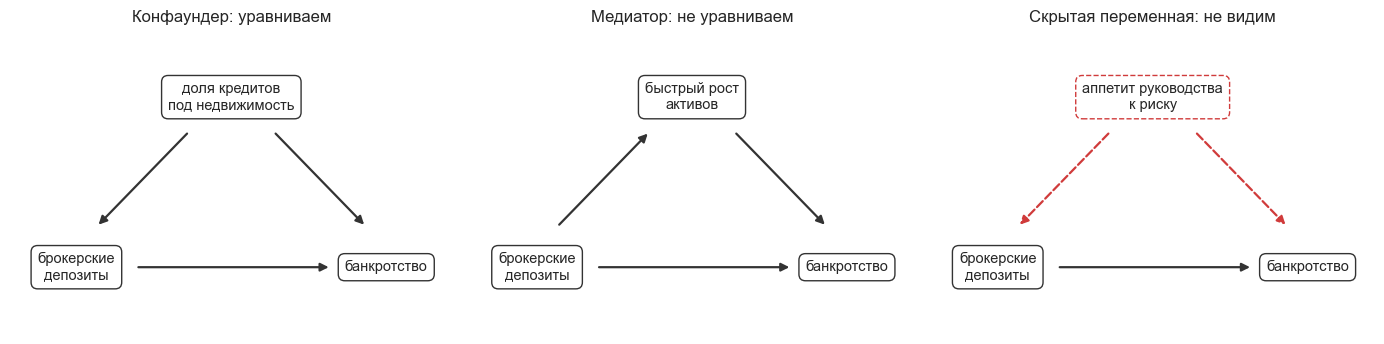

In [4]:
# @title Рисунок: конфаундер, медиатор, скрытая переменная
def node(ax, xy, text, hidden=False):
    # Прямоугольник с подписью; скрытая переменная — пунктиром
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                      edgecolor=HIDDEN_COLOR if hidden else "#333333", linestyle="--" if hidden else "-"))

def arrow(ax, start, end, hidden=False):
    # Стрелка «влияет»; от скрытой переменной — пунктиром
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", lw=1.6, color=HIDDEN_COLOR if hidden else "#333333",
                                linestyle="--" if hidden else "-", shrinkA=0, shrinkB=0))

T, Y, TOP = (0.15, 0.22), (0.85, 0.22), (0.5, 0.78)
# Концы стрелок у краёв рамок: слева направо, сверху вниз и снизу вверх
T_RIGHT, Y_LEFT = (0.29, 0.22), (0.72, 0.22)
TOP_LEFT, TOP_RIGHT = (0.40, 0.66), (0.60, 0.66)
T_TOP, Y_TOP = (0.20, 0.36), (0.80, 0.36)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
titles = ["Конфаундер: уравниваем", "Медиатор: не уравниваем", "Скрытая переменная: не видим"]
middle = ["доля кредитов\nпод недвижимость", "быстрый рост\nактивов", "аппетит руководства\nк риску"]
for k in range(3):
    ax = axes[k]
    node(ax, T, "брокерские\nдепозиты")
    node(ax, Y, "банкротство")
    node(ax, TOP, middle[k], hidden=(k == 2))
    arrow(ax, T_RIGHT, Y_LEFT)                        # эффект, который ищем
    if k == 1:                                        # медиатор лежит на пути эффекта
        arrow(ax, T_TOP, TOP_LEFT)
        arrow(ax, TOP_RIGHT, Y_TOP)
    else:                                             # конфаундер влияет на оба
        arrow(ax, TOP_LEFT, T_TOP, hidden=(k == 2))
        arrow(ax, TOP_RIGHT, Y_TOP, hidden=(k == 2))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.set_title(titles[k], fontsize=12)
plt.tight_layout()
plt.show()

- **Конфаундер** (confounder) влияет и на выбор банка, и на исход. Банк, который много кредитует под коммерческую недвижимость, чаще берёт брокерские депозиты и чаще разоряется. Если такая переменная есть в данных, её можно уравнять.
- **Медиатор** (mediator) лежит на пути эффекта. Брокерские депозиты позволяют быстро расти, а быстрый рост ведёт к банкротству. Уравнивать медиатор нельзя: так мы отрежем часть того самого эффекта, который ищем.
- **Скрытая переменная** — конфаундер, которого в данных нет, например аппетит руководства к риску. Уравнять её напрямую нельзя. Методы ниже обходят эту проблему по-разному, в чем и состоит их различие. 

## 2. Сопоставление по склонности (PSM)

Идея **сопоставления** (matching): для каждого банка с брокерскими депозитами найти похожие банки без них. Доля банкротств среди этих двойников и будет контрфактуалом.

Берём тот же срез, что в L06: балансы на 31 декабря 2006 года, за год до кризиса, одна строка — банк. Вмешательство — брокерские депозиты больше 5 % всех депозитов банка. Исход — банкротство в 2008–2012 годах. Двойников будем искать по девяти признакам CAMELS и бизнес-модели.

In [5]:
# Снимок на 31.12.2006, как в L06: одна строка — банк с активами больше 50 млн $
banks = panel[(panel["repdte"] == "2006-12-31") & (panel["assets"] > 50_000)].copy()
banks["log_assets"] = np.log10(banks["assets"] * 1000)            # размер: log10 активов в $

# Девять признаков, по которым ищем двойников
FEATURES = ["log_assets", "c_equity_assets", "a_npl_gross_loans", "e_roa", "a_cre_concentration",
            "m_asset_growth_yoy", "l_loans_deposits", "s_securities_assets", "l_liquid_assets_ratio"]
NAMES = {"log_assets": "размер", "c_equity_assets": "капитал / активы",
         "a_npl_gross_loans": "просрочка / кредиты", "e_roa": "ROA",
         "a_cre_concentration": "недвижимость / кредиты", "m_asset_growth_yoy": "рост активов за год",
         "l_loans_deposits": "кредиты / депозиты", "s_securities_assets": "ценные бумаги / активы",
         "l_liquid_assets_ratio": "ликвидные активы / активы"}
banks = banks.dropna(subset=FEATURES + ["l_brokered_share"])      # банки без пропусков

# Банки, обанкротившиеся ещё в 2007 году, из сравнения убираем: их исход 2008–2012 не определён
early = failures[failures["fail_date"] < "2008-01-01"]
banks = banks[~banks["cert"].isin(early["cert"])]

# Исход: банкротство в 2008–2012 годах. ASSISTANCE не считаем, как в L06
crisis = failures[(failures["restype"] == "FAILURE")
                  & failures["fail_date"].between("2008-01-01", "2012-12-31")]
banks["failed"] = banks["cert"].isin(crisis["cert"]).astype(int)

# Вмешательство: брокерские депозиты больше 5 % всех депозитов
banks["brokered"] = (banks["l_brokered_share"] > 0.05).astype(int)

# Обрезаем хвосты признаков по 1-му и 99-му перцентилям
lower = banks[FEATURES].quantile(0.01)
upper = banks[FEATURES].quantile(0.99)
banks[FEATURES] = banks[FEATURES].clip(lower, upper, axis=1)
banks = banks.reset_index(drop=True)                               # строки по порядку: 0, 1, 2, ...

print("банков:", len(banks), "| с брокерскими депозитами:", banks["brokered"].sum(),
      "| обанкротились в 2008–2012:", banks["failed"].sum())

банков: 1670 | с брокерскими депозитами: 527 | обанкротились в 2008–2012: 400


### 2.1 Наивное сравнение

In [6]:
naive_rates = banks.groupby("brokered")["failed"].mean()          # доля банкротств в каждой группе
naive = naive_rates[1] - naive_rates[0]                            # наивная разница
print(f"с брокерскими депозитами:  {naive_rates[1]:.1%} банкротств")
print(f"без брокерских депозитов:  {naive_rates[0]:.1%}")
print(f"наивная разница: {naive * 100:+.1f} п.п.")

с брокерскими депозитами:  45.0% банкротств
без брокерских депозитов:  14.3%
наивная разница: +30.7 п.п.


Банки с брокерскими депозитами разорялись втрое чаще. Абсолютные числа завышены дизайном выборки: в панели курса все обанкротившиеся банки и только 2000 случайных выживших (L04, L06). Во всей банковской системе США за 2008–2012 годы обанкротились 465 банков из примерно 8.7 тыс. Поэтому все доли и разницы в п.п. ниже относятся к выборке курса. Методы мы сравниваем на одной и той же выборке, что корректно.

Сколько из 31 п.п. — эффект брокерских депозитов, а сколько — смещение отбора? Чтобы ответить, нужны двойники.

### 2.2 Склонность: логит из L04 с другой целевой

Искать двойников сразу по девяти признакам неудобно: расстояние в девятимерном пространстве зависит от того, как взвесить признаки (L06 §1). **Склонность** (propensity score) сводит их к одному числу: это вероятность получить вмешательство при данных признаках, $e(x) = P(T{=}1 \mid x)$. Rosenbaum и Rubin (1983) показали: у банков с одинаковой склонностью признаки, вошедшие в неё, распределены одинаково, будь у банка брокерские депозиты или нет.

Оценим склонность логитом из L04. Целевая теперь — брокерские депозиты, а не банкротство.

In [ ]:
# Стандартизуем признаки, как в L03 и L06
X = (banks[FEATURES] - banks[FEATURES].mean()) / banks[FEATURES].std()

# Логит: P(брокерские депозиты | девять признаков)
ps_model = LogisticRegression(max_iter=5000)
ps_model.fit(X, banks["brokered"])
banks["ps"] = ps_model.predict_proba(X)[:, 1]                     # склонность каждого банка
banks["ps_logit"] = np.log(banks["ps"] / (1 - banks["ps"]))       # она же в лог-шансах

# Склонность в двух группах: минимум, квартили, максимум
banks.groupby("brokered")["ps"].describe()[["min", "25%", "50%", "75%", "max"]].round(3)

,min,25%,50%,75%,max
brokered,,,,,
0,0.002,0.097,0.204,0.361,0.971
1,0.010,0.316,0.460,0.597,0.949


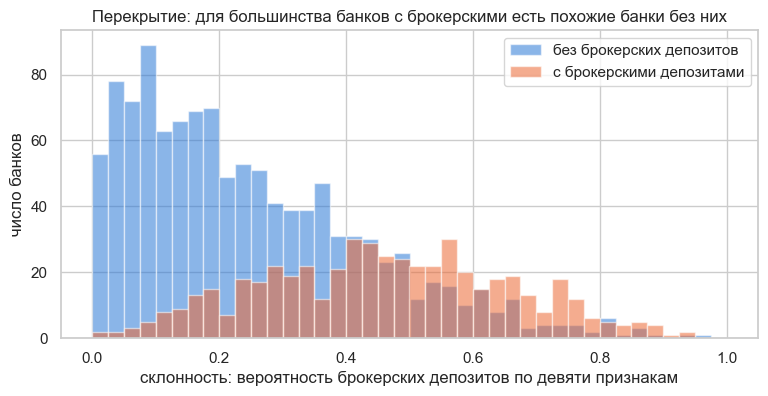

In [8]:
# @title Рисунок: перекрытие склонностей
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(0, 1, 41)
ax.hist(banks.loc[banks["brokered"] == 0, "ps"], bins=bins, alpha=0.55, color=CONTROL_COLOR,
        label="без брокерских депозитов")
ax.hist(banks.loc[banks["brokered"] == 1, "ps"], bins=bins, alpha=0.55, color=TREATED_COLOR,
        label="с брокерскими депозитами")
ax.set_xlabel("склонность: вероятность брокерских депозитов по девяти признакам")
ax.set_ylabel("число банков")
ax.set_title("Перекрытие: для большинства банков с брокерскими есть похожие банки без них")
ax.legend()
plt.show()

Признаки и правда предсказывают брокерские депозиты: у трёх четвертей банков без них склонность ниже 0.36, а у половины банков с ними она между 0.32 и 0.60. Но **перекрытие** (overlap) хорошее: почти для каждого банка с брокерскими депозитами найдутся банки без них с той же склонностью. Выше 0.8 банков без брокерских мало, и двойники там будут повторяться.

### 2.3 Двойники

Для каждого банка с брокерскими депозитами возьмём пять банков без них с ближайшей склонностью. Это ближайшие соседи из L01: там соседи давали прогноз, здесь они сами и есть ответ. Один банк может стать двойником нескольких банков: это сопоставление с возвращением (matching with replacement). Расстояние меряем по лог-шансам склонности: около 0 и 1 они различают банки лучше самой вероятности.

In [9]:
K = 5                                                       # сколько двойников у каждого банка
treated = banks[banks["brokered"] == 1]                     # банки с брокерскими депозитами
control = banks[banks["brokered"] == 0]                     # банки без них: отсюда берём двойников

neighbors = NearestNeighbors(n_neighbors=K)                 # поиск ближайших соседей
neighbors.fit(control[["ps_logit"]])                        # ищем среди банков без брокерских
distance, position = neighbors.kneighbors(treated[["ps_logit"]])   # K ближайших для каждого банка

twins = control.iloc[position.ravel()]                      # все двойники подряд, с повторами
print("банков с брокерскими депозитами:", len(treated), "| двойников:", len(twins))
print("различных банков среди двойников:", twins["cert"].nunique(), "из", len(control))

банков с брокерскими депозитами: 527 | двойников: 2635
различных банков среди двойников: 718 из 1143


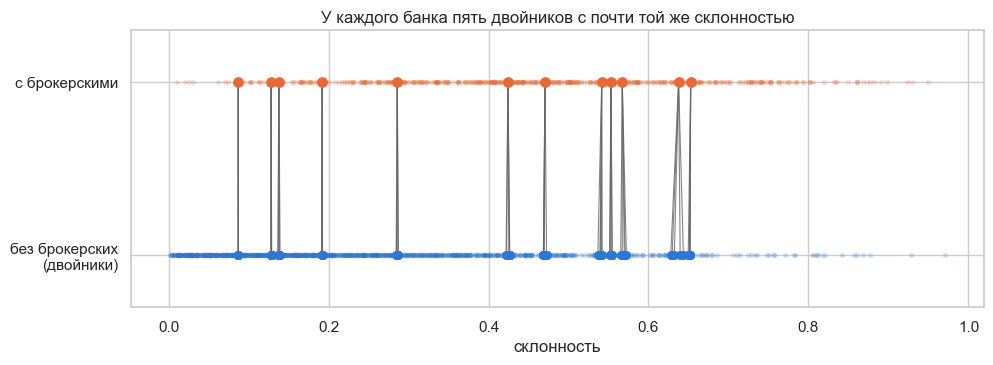

In [10]:
# @title Рисунок: двенадцать банков и их двойники
rng = np.random.default_rng(SEED)
shown = rng.choice(len(treated), 12, replace=False)         # двенадцать случайных банков с брокерскими
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.scatter(control["ps"], np.zeros(len(control)), s=8, color=CONTROL_COLOR, alpha=0.15)
ax.scatter(treated["ps"], np.ones(len(treated)), s=8, color=TREATED_COLOR, alpha=0.15)
for i in shown:
    x_treated = treated["ps"].iloc[i]
    for j in position[i]:
        x_twin = control["ps"].iloc[j]
        ax.plot([x_treated, x_twin], [1, 0], color="#666666", lw=0.8, alpha=0.8)
        ax.scatter(x_twin, 0, s=30, color=CONTROL_COLOR, zorder=3)
    ax.scatter(x_treated, 1, s=45, color=TREATED_COLOR, zorder=3)
ax.set_yticks([0, 1])
ax.set_yticklabels(["без брокерских\n(двойники)", "с брокерскими"])
ax.set_ylim(-0.3, 1.3)
ax.set_xlabel("склонность")
ax.set_title("У каждого банка пять двойников с почти той же склонностью")
plt.show()

### 2.4 Баланс до и после

Проверим, сработало ли сопоставление. Сравним средние признаков у банков с брокерскими депозитами и у двух групп сравнения: у всех банков без брокерских и у двойников. Разницу меряем в стандартных отклонениях: это **стандартизованная разница средних** (standardized mean difference, SMD). Признак принято считать уравненным, если $|SMD| < 0.1$.

In [11]:
def smd(a, b):
    # Стандартизованная разница средних: разница средних в долях общего стандартного отклонения
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

balance = pd.DataFrame(index=[NAMES[f] for f in FEATURES])
for feature in FEATURES:
    balance.loc[NAMES[feature], "до: все без брокерских"] = smd(treated[feature], control[feature])
    balance.loc[NAMES[feature], "после: двойники"] = smd(treated[feature], twins[feature])
balance.round(2)

,до: все без брокерских,после: двойники
размер,0.32,0.01
капитал / активы,-0.09,-0.01
просрочка / кредиты,0.14,0.00
ROA,0.02,0.06
недвижимость / кредиты,0.64,0.03
рост активов за год,0.43,0.01
кредиты / депозиты,0.77,-0.04
ценные бумаги / активы,-0.65,0.06
ликвидные активы / активы,-0.74,0.04


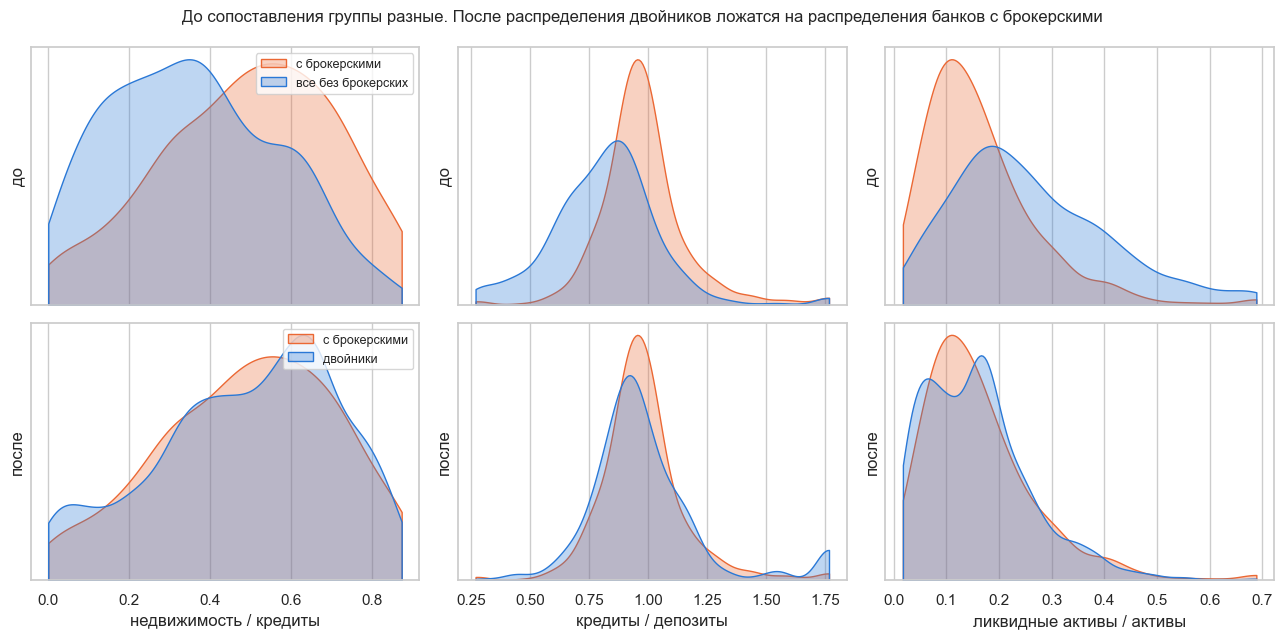

In [12]:
# @title Рисунок: распределения до и после сопоставления
shown_features = ["a_cre_concentration", "l_loans_deposits", "l_liquid_assets_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex="col")
for col in range(3):
    feature = shown_features[col]
    for row, (comparison, label) in enumerate([(control, "все без брокерских"), (twins, "двойники")]):
        ax = axes[row, col]
        sns.kdeplot(treated[feature], ax=ax, color=TREATED_COLOR, fill=True, alpha=0.3, cut=0, label="с брокерскими")
        sns.kdeplot(comparison[feature], ax=ax, color=CONTROL_COLOR, fill=True, alpha=0.3, cut=0, label=label)
        ax.set_xlabel(NAMES[feature])
        ax.set_ylabel("до" if row == 0 else "после")
        ax.set_yticks([])
        if col == 0:
            ax.legend(fontsize=9, loc="upper right")
fig.suptitle("До сопоставления группы разные. После распределения двойников ложатся на распределения банков с брокерскими",
             fontsize=12)
plt.tight_layout()
plt.show()

До сопоставления банки с брокерскими депозитами сильно отличались от остальных. У них больше кредитов под недвижимость (SMD 0.64) и выше отношение кредитов к депозитам (0.77), меньше ликвидных активов (−0.74) и бумаг (−0.65), они быстрее росли (0.43). После сопоставления ни один из девяти $|SMD|$ не превышает 0.06: по видимым признакам двойники неотличимы от банков с брокерскими депозитами.

### 2.5 Эффект

Двойники и есть контрфактуал. Их доля банкротств показывает, сколько банков с брокерскими депозитами обанкротилось бы, если бы у них были те же девять признаков, но не было брокерских депозитов.

In [13]:
fact = treated["failed"].mean()                    # банкротства банков с брокерскими: то, что было
counterfactual = twins["failed"].mean()            # банкротства их двойников: то, что было бы
att = fact - counterfactual                        # эффект для банков с брокерскими (ATT)
print(f"банки с брокерскими депозитами: {fact:.1%} банкротств")
print(f"их двойники:                    {counterfactual:.1%}")
print(f"эффект (ATT): {att * 100:+.1f} п.п.  |  наивная разница: {naive * 100:+.1f} п.п.")

банки с брокерскими депозитами: 45.0% банкротств
их двойники:                    33.2%
эффект (ATT): +11.8 п.п.  |  наивная разница: +30.7 п.п.


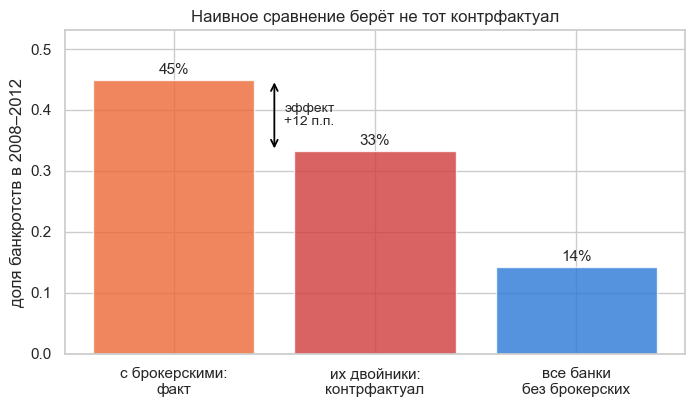

In [14]:
# @title Рисунок: факт, контрфактуал и наивное сравнение
values = [fact, counterfactual, naive_rates[0]]
labels = ["с брокерскими:\nфакт", "их двойники:\nконтрфактуал", "все банки\nбез брокерских"]
colors = [TREATED_COLOR, HIDDEN_COLOR, CONTROL_COLOR]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(labels, values, color=colors, alpha=0.8)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.0%}", ha="center", fontsize=11)
ax.annotate("", xy=(0.5, counterfactual), xytext=(0.5, fact),
            arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
ax.text(0.55, (fact + counterfactual) / 2, f"эффект\n{att * 100:+.0f} п.п.", va="center", fontsize=10)
ax.set_ylabel("доля банкротств в 2008–2012")
ax.set_ylim(0, max(values) * 1.18)
ax.set_title("Наивное сравнение берёт не тот контрфактуал")
plt.show()

Двойники обанкротились в 33 % случаев, банки с брокерскими депозитами — в 45 %. Эффект +11.8 п.п. против наивных +30.7: около двух третей наивной разницы — смещение отбора. Банки с брокерскими депозитами были рискованнее и без них.

Насколько точна оценка? Повторим всю процедуру на бутстрап-выборках банков, как в L03 §4: склонность, двойники, эффект. Чтобы не повторять код, соберём шаги §2.2–2.5 в одну функцию.

In [15]:
def psm_effect(data, features):
    # Шаги §2.2–2.5 подряд: склонность -> пять двойников -> эффект (ATT)
    X = (data[features] - data[features].mean()) / data[features].std()
    model = LogisticRegression(max_iter=5000).fit(X, data["brokered"])
    ps = model.predict_proba(X)[:, 1]
    ps_logit = np.log(ps / (1 - ps)).reshape(-1, 1)
    is_treated = data["brokered"].to_numpy() == 1
    neighbors = NearestNeighbors(n_neighbors=K).fit(ps_logit[~is_treated])
    _, position = neighbors.kneighbors(ps_logit[is_treated])
    failed = data["failed"].to_numpy()
    return failed[is_treated].mean() - failed[~is_treated][position.ravel()].mean()

print(f"проверка: функция даёт тот же эффект {psm_effect(banks, FEATURES) * 100:+.1f} п.п.")

# Бутстрап по банкам: 200 выборок с возвращением
rng = np.random.default_rng(SEED)
boot = []
for b in range(200):
    rows = rng.integers(0, len(banks), len(banks))                 # номера банков с повторами
    boot.append(psm_effect(banks.iloc[rows].reset_index(drop=True), FEATURES))
att_low, att_high = np.percentile(boot, [2.5, 97.5])
print(f"95%-й бутстрап-интервал: [{att_low * 100:+.1f}; {att_high * 100:+.1f}] п.п.")

проверка: функция даёт тот же эффект +11.8 п.п.


95%-й бутстрап-интервал: [+5.5; +18.7] п.п.


Интервал широкий, от +5.5 до +18.7 п.п., но ноль от него далеко. Оговорка: для сопоставления с фиксированным числом соседей бутстрап даёт лишь приближённый интервал (Abadie и Imbens, 2008). Для ориентира его достаточно.

### 2.6 Скрытые переменные: какой силы должна быть неизвестная

Сопоставление уравнивает только то, что мы видим. Если есть скрытый конфаундер, оценка смещена, и проверить это по данным нельзя. Зато можно прикинуть, насколько сильным он должен быть, чтобы изменить вывод. Спрячем по очереди каждый из девяти видимых признаков и посмотрим, насколько сдвинется оценка: так ведёт себя пропущенная переменная такой силы.

In [16]:
hidden = {}
for feature in FEATURES:
    others = FEATURES.copy()
    others.remove(feature)                                          # все признаки, кроме одного
    hidden[NAMES[feature]] = psm_effect(banks, others)              # эффект без этого признака
hidden = pd.Series(hidden).sort_values()
(hidden * 100).round(1)

ROA                          12.2
кредиты / депозиты           12.3
размер                       12.3
капитал / активы             13.4
ликвидные активы / активы    13.8
рост активов за год          14.0
ценные бумаги / активы       14.3
просрочка / кредиты          14.6
недвижимость / кредиты       15.1
dtype: float64

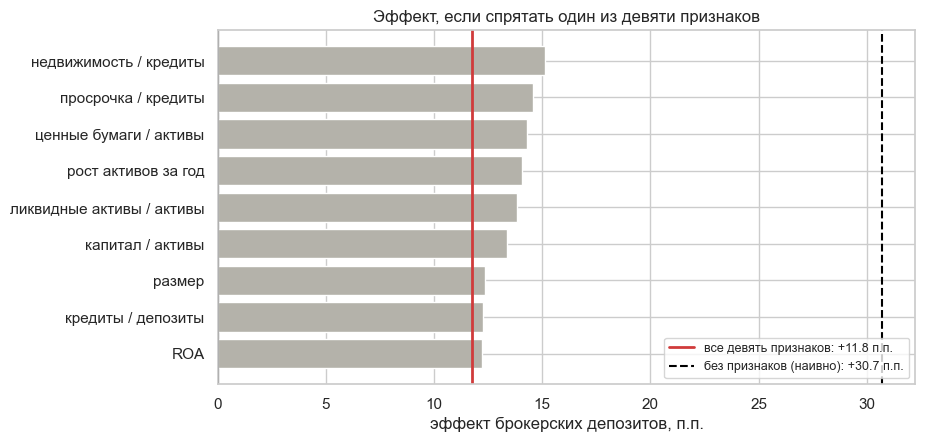

In [17]:
# @title Рисунок: эффект, если спрятать один признак
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(hidden.index, hidden * 100, color="#b4b2aa")
ax.axvline(att * 100, color=HIDDEN_COLOR, lw=2, label=f"все девять признаков: {att * 100:+.1f} п.п.")
ax.axvline(naive * 100, color="black", lw=1.5, ls="--", label=f"без признаков (наивно): {naive * 100:+.1f} п.п.")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("эффект брокерских депозитов, п.п.")
ax.set_title("Эффект, если спрятать один из девяти признаков")
ax.legend(loc="lower right", fontsize=9)
plt.show()

Какой бы признак мы ни спрятали, оценка растёт: с +11.8 до +12.2…+15.1 п.п. Пропущенный конфаундер приписывает брокерским депозитам риск, который на самом деле идёт от него. Сильнее всего сдвигает оценку концентрация в недвижимости: на +3.3 п.п.

Это рассуждение называется **анализом чувствительности** (sensitivity analysis). По тому, как сдвигают оценку видимые переменные, судим, какой силы должна быть невидимая, чтобы изменить вывод. Чтобы эффект исчез, скрытая переменная должна сдвинуть оценку на все 12 п.п., то есть быть в 3–4 раза сильнее концентрации в недвижимости, самого сильного из видимых конфаундеров.

Два нюанса. Видимые признаки во многом дублируют друг друга, поэтому выпадение одного почти не вредит: остальные его подменяют. Опаснее скрытая переменная, которую видимые признаки не заменяют, например тот самый аппетит руководства к риску. Кроме того, рост активов, возможно, медиатор (§1). Если брокерские депозиты помогали банкам расти, то, уравнивая рост, мы отрезаем часть эффекта, и ближе к полному эффекту оценка без роста: +14.0 п.п.

## 3. Разность разностей (DiD)

РSM исходит из того, что все конфаундеры видны. **Разность разностей** (difference-in-differences, DiD) обходится без этого, если в данных есть время: она сравнивает изменения, а не уровни. Всё, чем группы различались постоянно, при вычитании «после минус до» сокращается, даже если мы этого не видим.

Пример — рост ставок 2022 года. С марта 2022 года ФРС подняла ставку почти с нуля до 4.25–4.5 % к декабрю, и облигации подешевели. Банки держат часть активов в облигациях, а переоценка бумаг, которые банк держит для продажи (available for sale, AFS), идёт прямо в балансовый капитал. Значит, у банков с большой долей бумаг капитал должен был просесть сильнее.

Вмешательство здесь — доля бумаг, с которой банк вошёл в 2022 год. Делим банки на три равные группы по доле ценных бумаг в активах на 31.12.2021 и смотрим на капитал / активы с 2019 по 2025 год. Берём только банки, которые отчитывались все 28 кварталов: так состав групп не меняется.

In [18]:
# Отчёты 2019–2025 годов банков с активами больше 50 млн $
shock = panel[(panel["repdte"] >= "2019-03-31") & (panel["repdte"] <= "2025-12-31")
              & (panel["assets"] > 50_000)].copy()

# Оставляем банки, у которых есть все кварталы окна
n_quarters = shock["repdte"].nunique()
quarters_per_bank = shock.groupby("cert")["repdte"].nunique()
shock = shock[shock["cert"].isin(quarters_per_bank[quarters_per_bank == n_quarters].index)]
shock = shock.dropna(subset=["c_equity_assets", "c_tier1_leverage"]).copy()

# Три группы по доле ценных бумаг на 31.12.2021 — до роста ставок
start = shock[shock["repdte"] == "2021-12-31"].set_index("cert")["s_securities_assets"]
group = pd.qcut(start, 3, labels=["мало бумаг", "средне", "много бумаг"])
shock["group"] = shock["cert"].map(group)

# Капитал / активы (балансовый) и tier 1 / активы (регуляторный) в процентах, хвосты обрезаем
for column in ["c_equity_assets", "c_tier1_leverage"]:
    low, high = shock[column].quantile([0.01, 0.99])
    shock[column] = shock[column].clip(low, high)
shock["equity"] = shock["c_equity_assets"] * 100
shock["tier1"] = shock["c_tier1_leverage"] * 100

print("банков:", shock["cert"].nunique(), "| кварталов:", n_quarters)
print("границы групп по доле бумаг:", start.quantile([1 / 3, 2 / 3]).round(3).tolist())
print(shock.drop_duplicates("cert")["group"].value_counts().to_string())

банков: 752 | кварталов: 28
границы групп по доле бумаг: [0.141, 0.3]
group
мало бумаг     251
много бумаг    251
средне         250


In [19]:
# Средний капитал / активы по группам и кварталам
by_group = shock.groupby(["repdte", "group"], observed=True)["equity"].mean().unstack()
print("перед ростом ставок и на дне, %:")
print(by_group.loc[["2021-12-31", "2022-09-30"]].round(2))

перед ростом ставок и на дне, %:
group       мало бумаг  средне  много бумаг
repdte                                     
2021-12-31       11.42   10.32        10.95
2022-09-30       11.03    8.81         7.17


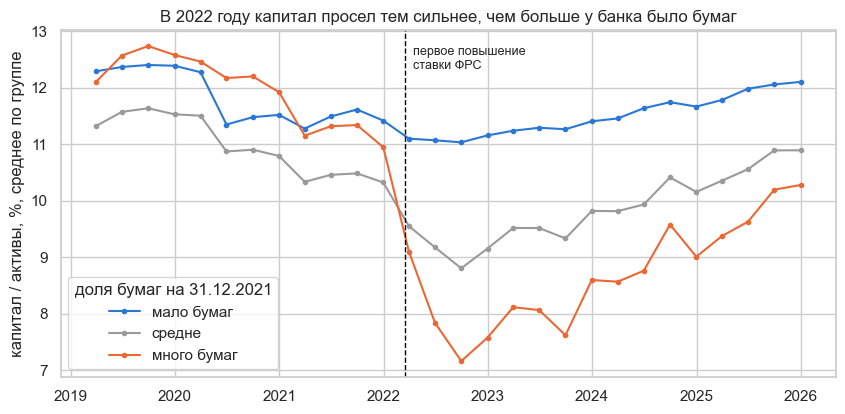

In [20]:
# @title Рисунок: капитал / активы в трёх группах банков
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {"мало бумаг": CONTROL_COLOR, "средне": "#9a9a9a", "много бумаг": TREATED_COLOR}
for name in ["мало бумаг", "средне", "много бумаг"]:
    ax.plot(by_group.index, by_group[name], marker="o", ms=3, color=colors[name], label=name)
ax.axvline(pd.Timestamp("2022-03-16"), color="black", lw=1, ls="--")
ax.text(pd.Timestamp("2022-04-15"), by_group.max().max(), "первое повышение\nставки ФРС", fontsize=9, va="top")
ax.set_ylabel("капитал / активы, %, среднее по группе")
ax.set_title("В 2022 году капитал просел тем сильнее, чем больше у банка было бумаг")
ax.legend(title="доля бумаг на 31.12.2021")
plt.show()

В группах по 250 банков: до 14 % бумаг в активах, от 14 до 30 % и больше 30 %. До 2022 года крайние группы идут почти вместе. К сентябрю 2022 года капитал / активы банков с большой долей бумаг падает с 10.95 до 7.17 %, у банков с малой долей — с 11.42 до 11.03 %, средняя группа посередине. Чем больше бумаг, тем сильнее удар. Такая зависимость «доза — ответ» — один из признаков того, что дело именно в бумагах.

### 3.1 Таблица 2 × 2

Простейшая DiD — таблица из двух групп (много и мало бумаг) и двух периодов (2019–2021 и 2022–2023). Среднюю группу пока откладываем.

In [21]:
# Две крайние группы, 2019–2023 годы
two = shock[shock["group"].isin(["мало бумаг", "много бумаг"]) & (shock["repdte"] <= "2023-12-31")].copy()
two["treated"] = (two["group"] == "много бумаг").astype(int)       # 1 — много бумаг
two["post"] = (two["repdte"] >= "2022-01-01").astype(int)          # 1 — после роста ставок

table = two.groupby(["treated", "post"])["equity"].mean().unstack()
table.index = ["мало бумаг", "много бумаг"]
table.columns = ["2019–2021", "2022–2023"]
table["изменение"] = table["2022–2023"] - table["2019–2021"]
did = table.loc["много бумаг", "изменение"] - table.loc["мало бумаг", "изменение"]
print(table.round(2))
print(f"\nразность разностей: {did:+.2f} п.п.")

             2019–2021  2022–2023  изменение
мало бумаг       11.82      11.20      -0.63
много бумаг      11.96       8.01      -3.95

разность разностей: -3.32 п.п.


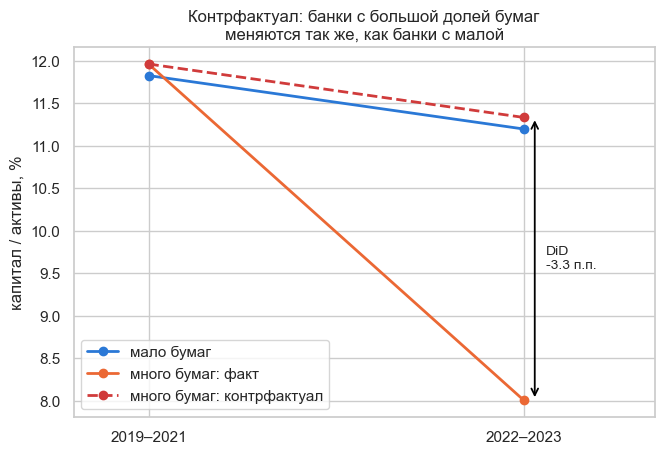

In [22]:
# @title Рисунок: разность разностей и контрфактуал
x = [0, 1]
control_line = table.loc["мало бумаг", ["2019–2021", "2022–2023"]].to_numpy()
treated_line = table.loc["много бумаг", ["2019–2021", "2022–2023"]].to_numpy()
counterfactual_line = [treated_line[0], treated_line[0] + (control_line[1] - control_line[0])]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(x, control_line, marker="o", color=CONTROL_COLOR, lw=2, label="мало бумаг")
ax.plot(x, treated_line, marker="o", color=TREATED_COLOR, lw=2, label="много бумаг: факт")
ax.plot(x, counterfactual_line, marker="o", color=HIDDEN_COLOR, lw=2, ls="--",
        label="много бумаг: контрфактуал")
ax.annotate("", xy=(1.03, treated_line[1]), xytext=(1.03, counterfactual_line[1]),
            arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
ax.text(1.06, (treated_line[1] + counterfactual_line[1]) / 2, f"DiD\n{did:+.1f} п.п.", va="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(["2019–2021", "2022–2023"])
ax.set_xlim(-0.2, 1.35)
ax.set_ylabel("капитал / активы, %")
ax.set_title("Контрфактуал: банки с большой долей бумаг\nменяются так же, как банки с малой")
ax.legend(loc="lower left")
plt.show()

Банки с малой долей бумаг показывают, как изменился бы капитал банков с большой долей без удара по бумагам: снизился бы на 0.63 п.п. Такие общие для всех изменения есть всегда, например приток депозитов в 2020–2021 годах раздул активы быстрее капитала. Фактически капитал банков с большой долей бумаг снизился на 3.95 п.п. Разность разностей: $-3.95 - (-0.63) = -3.32$ п.п.

Красный пунктир на рисунке — контрфактуал: путь банков с большой долей бумаг, если бы они менялись так же, как банки с малой. Это допущение называется **предпосылкой параллельных трендов** (parallel trends): без вмешательства группы менялись бы одинаково, хотя уровни у них могут быть разными.

### 3.2 DiD как регрессия

Ту же разность разностей даёт регрессия со взаимодействием из L01: `equity ~ treated + post + treated:post`. Коэффициент при `treated:post` и есть DiD, а регрессия добавляет к нему стандартную ошибку. Ошибки кластерные по банку (L02): кварталы одного банка между собой не независимы.

In [23]:
did_model = smf.ols("equity ~ treated + post + treated:post", data=two).fit(
    cov_type="cluster", cov_kwds={"groups": two["cert"]})       # кластерные ошибки по банку
did_model.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,11.8232,0.289,40.954,0.000,11.257,12.389
treated,0.1358,0.367,0.370,0.712,-0.584,0.856
post,-0.6274,0.113,-5.542,0.000,-0.849,-0.405
treated:post,-3.3197,0.162,-20.554,0.000,-3.636,-3.003


Коэффициент при `treated:post` равен −3.32, как в таблице 2 × 2, а его 95%-й интервал — от −3.64 до −3.00. Остальные коэффициенты — клетки той же таблицы. `Intercept` (11.82) — банки с малой долей бумаг до 2022 года, `treated` (+0.14) — разница групп до 2022 года, `post` (−0.63) — изменение у банков с малой долей.

### 3.3 Проверка параллельных трендов: event study

После 2022 года параллельность проверить нельзя: контрфактуал не наблюдается. Зато можно проверить до. Если в 2019–2021 годах группы шли параллельно, предпосылка правдоподобнее. Для этого считают разрыв между группами в каждом квартале, это **event study**: в регрессии взаимодействие `treated` с каждым кварталом.

In [24]:
pair = shock[shock["group"].isin(["мало бумаг", "много бумаг"])].copy()   # крайние группы, все кварталы
pair["treated"] = (pair["group"] == "много бумаг").astype(int)
pair["quarter"] = pair["repdte"].dt.strftime("%Y-%m")                     # квартал как категория

event_model = smf.ols("equity ~ C(quarter) + C(quarter):treated", data=pair).fit(
    cov_type="cluster", cov_kwds={"groups": pair["cert"]})

# Разрыв «много бумаг» минус «мало бумаг» в каждом квартале и его 95%-й интервал
gaps = pd.DataFrame({"разрыв": event_model.params, "от": event_model.conf_int()[0],
                     "до": event_model.conf_int()[1]})
gaps = gaps[gaps.index.str.endswith(":treated")]                         # только разрывы
gaps.index = pd.to_datetime(gaps.index.str[11:18])                       # "C(quarter)[2019-03]:treated" -> дата
pre_gaps = gaps[gaps.index < "2022-01-01"]                                  # кварталы до роста ставок
print("разрыв до 2022 года: от", round(pre_gaps["разрыв"].min(), 2), "до", round(pre_gaps["разрыв"].max(), 2), "п.п.;",
      "интервал не накрывает ноль в", ((pre_gaps["от"] > 0) | (pre_gaps["до"] < 0)).sum(), "из", len(pre_gaps), "кварталов")
print("самый глубокий разрыв:", round(gaps["разрыв"].min(), 2), "п.п. в",
      gaps["разрыв"].idxmin().strftime("%Y-%m"), "| в конце 2025 года:", round(gaps["разрыв"].iloc[-1], 2))

разрыв до 2022 года: от -0.47 до 0.82 п.п.; интервал не накрывает ноль в 1 из 12 кварталов
самый глубокий разрыв: -3.87 п.п. в 2022-09 | в конце 2025 года: -1.82


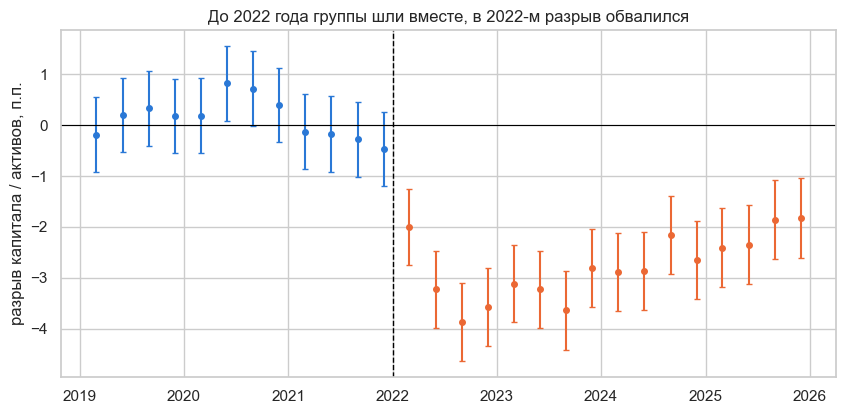

In [25]:
# @title Рисунок: разрыв по кварталам (event study)
fig, ax = plt.subplots(figsize=(10, 4.5))
before = gaps.index < "2022-01-01"
for mask, color in [(before, CONTROL_COLOR), (~before, TREATED_COLOR)]:
    part = gaps[mask]
    ax.errorbar(part.index, part["разрыв"], yerr=[part["разрыв"] - part["от"], part["до"] - part["разрыв"]],
                fmt="o", ms=4, color=color, capsize=2)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(pd.Timestamp("2022-01-01"), color="black", lw=1, ls="--")
ax.set_ylabel("разрыв капитала / активов, п.п.")
ax.set_title("До 2022 года группы шли вместе, в 2022-м разрыв обвалился")
plt.show()

До 2022 года разрыв колеблется от −0.47 до +0.82 п.п., и интервал не накрывает ноль только в одном квартале из двенадцати. Колебания объясняет тот же механизм в малом масштабе. В 2020 году ставки упали, бумаги подорожали, и разрыв ушёл в плюс; в 2021 году долгосрочные ставки немного выросли, и он стал отрицательным. В 2022 году разрыв обваливается до −3.87 п.п. к сентябрю, а к концу 2025 года восстанавливается лишь наполовину, до −1.82: бумаги постепенно гасятся, и переоценка уходит.

DiD прощает постоянные различия между группами, видимые и скрытые: банки с большой долей бумаг могут быть консервативнее, у них могут быть другие клиенты. Если бы в 2022 году с одной из групп случилось что-то ещё, DiD приписал бы это ставкам. Ровные разрывы до события такую возможность не исключают, они лишь делают её менее вероятной.

### 3.4 Скрытая переменная: что видел надзор

Посмотрим на другой капитал — регуляторный: tier 1 к активам (`c_tier1_leverage`). По американским правилам 2013 года большинство банков могли не включать переоценку AFS-бумаг в регуляторный капитал и так и делали. А бумаги, которые банк собирается держать до погашения (held to maturity, HTM), не переоцениваются даже в балансе.

In [26]:
# Та же DiD для регуляторного капитала
tier1_model = smf.ols("tier1 ~ treated + post + treated:post", data=two).fit(
    cov_type="cluster", cov_kwds={"groups": two["cert"]})
for name, model in [("балансовый капитал / активы", did_model), ("tier 1 / активы", tier1_model)]:
    low, high = model.conf_int().loc["treated:post"]
    print(f"{name:28s} DiD {model.params['treated:post']:+.2f} п.п.  [{low:+.2f}; {high:+.2f}]")

балансовый капитал / активы  DiD -3.32 п.п.  [-3.64; -3.00]
tier 1 / активы              DiD -0.14 п.п.  [-0.36; +0.08]


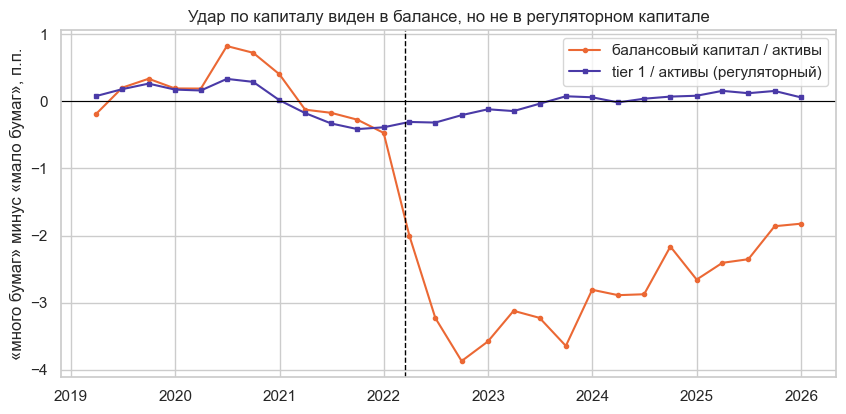

In [27]:
# @title Рисунок: балансовый и регуляторный капитал
tier1_by_group = pair.groupby(["repdte", "treated"])["tier1"].mean().unstack()
equity_by_group = pair.groupby(["repdte", "treated"])["equity"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(equity_by_group.index, equity_by_group[1] - equity_by_group[0], marker="o", ms=3,
        color=TREATED_COLOR, label="балансовый капитал / активы")
ax.plot(tier1_by_group.index, tier1_by_group[1] - tier1_by_group[0], marker="s", ms=3,
        color="#4a3aa7", label="tier 1 / активы (регуляторный)")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(pd.Timestamp("2022-03-16"), color="black", lw=1, ls="--")
ax.set_ylabel("«много бумаг» минус «мало бумаг», п.п.")
ax.set_title("Удар по капиталу виден в балансе, но не в регуляторном капитале")
ax.legend()
plt.show()

По регуляторному капиталу удара почти не было: DiD по tier 1 равен −0.14 п.п., интервал от −0.36 до +0.08 накрывает ноль. Модели L04–L05 учились на балансовом капитале, надзор смотрел на регуляторный. Той части убытка, которая сидела в HTM-бумагах, не было ни в том, ни в другом.

Именно так было у Silicon Valley Bank (SVB). Около трёх четвертей его бумаг числились HTM, и нереализованный убыток по ним к концу 2022 года составлял около 15 млрд $ при капитале около 16 млрд $ (годовой отчёт банка за 2022 год). В отчётности FDIC этого убытка нет:

In [28]:
# Silicon Valley Bank в отчётности FDIC: доля бумаг, балансовый и регуляторный капитал
svb = panel[(panel["cert"] == 24735) & (panel["repdte"] >= "2021-12-31")]
svb.set_index("repdte")[["s_securities_assets", "c_equity_assets", "c_tier1_leverage"]].round(3)

,s_securities_assets,c_equity_assets,c_tier1_leverage
repdte,,,
2021-12-31,0.601,0.071,0.074
2022-03-31,0.572,0.067,0.071
2022-06-30,0.576,0.073,0.076
2022-09-30,0.570,0.072,0.080
2022-12-31,0.561,0.074,0.081


Бумаги занимают 56–60 % активов, балансовый капитал / активы весь 2022 год держится на 6.7–7.4 %, а регуляторный даже растёт: с 7.4 % в конце 2021 года до 8.1 % в конце 2022-го. Логит L04 (§5.2) дал SVB по последнему отчёту 2022 года 0.07 % вероятности банкротства.

Это и есть скрытая переменная: в мире она есть, а в данных её нет. DiD нашёл её след там, где она видна, — в AFS-бумагах и балансовом капитале. Случай SVB показывает, чего стоит её не видеть.

## 4. Синтетический контроль (SC)

DiD нужна контрольная группа, которая шла параллельно. Что делать, если такой группы нет, а обработанная единица одна, например один штат? **Синтетический контроль** (synthetic control; Abadie и Gardeazabal, 2003; Abadie, Diamond и Hainmueller, 2010) собирает контрольную единицу из смеси доноров. Веса подбираются так, чтобы смесь повторяла путь обработанной единицы до события.

Пример — ураган «Катрина». 29 августа 2005 года он разрушил побережье Луизианы и Миссисипи. Что стало с депозитами банков этих штатов? Для каждого банка строим индекс депозитов: депозиты, делённые на депозиты 30.06.2005, × 100. Единица вмешательства — среднее по банкам Луизианы и Миссисипи (LA+MS). Доноры — средние по банкам других штатов, где не меньше 12 банков отчитывались каждый квартал 2001–2006 годов. Алабаму, Флориду и Техас из доноров убираем: их тоже задели ураганы 2005 года.

In [29]:
# Отчёты 2001–2006 годов; оставляем банки, у которых есть все 24 квартала
storm = panel[(panel["repdte"] >= "2001-03-31") & (panel["repdte"] <= "2006-12-31")].copy()
n_quarters = storm["repdte"].nunique()
quarters_per_bank = storm.groupby("cert")["repdte"].nunique()
before_storm = storm[storm["repdte"] == "2005-06-30"].set_index("cert")     # последний отчёт до урагана
keep = quarters_per_bank[quarters_per_bank == n_quarters].index
keep = keep.intersection(before_storm[before_storm["assets"] > 50_000].index)
storm = storm[storm["cert"].isin(keep) & ~storm["state"].isin(["AL", "FL", "TX"])].copy()

# Индекс депозитов: 30.06.2005 = 100; хвосты обрезаем (слияния дают скачки)
storm["deposit_index"] = storm["deposits"] / storm["cert"].map(before_storm["deposits"]) * 100
low, high = storm["deposit_index"].quantile([0.01, 0.99])
storm["deposit_index"] = storm["deposit_index"].clip(low, high)
storm["unit"] = np.where(storm["state"].isin(["LA", "MS"]), "LA+MS", storm["state"])

# Средний индекс по штатам, где не меньше 12 банков
banks_per_unit = storm[storm["repdte"] == "2005-06-30"].groupby("unit").size()
units = banks_per_unit[banks_per_unit >= 12].index
by_state = storm[storm["unit"].isin(units)].groupby(["repdte", "unit"])["deposit_index"].mean().unstack()
donors = [unit for unit in by_state.columns if unit != "LA+MS"]
before = by_state.index <= "2005-06-30"                                   # кварталы до урагана
print("банков LA+MS:", banks_per_unit["LA+MS"], "| штатов-доноров:", len(donors),
      "| кварталов до урагана:", before.sum(), "| после:", (~before).sum())

банков LA+MS: 46 | штатов-доноров: 31 | кварталов до урагана: 18 | после: 6


### 4.1 Простое сравнение не работает

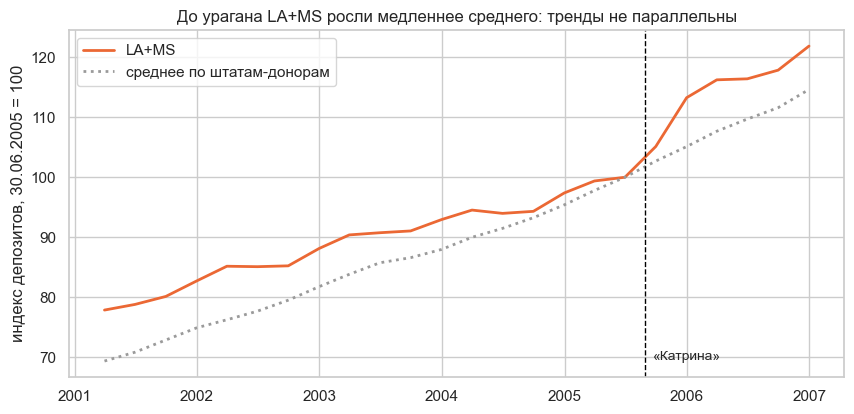

In [30]:
# @title Рисунок: LA+MS против среднего по штатам
average = by_state[donors].mean(axis=1)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(by_state.index, by_state["LA+MS"], color=TREATED_COLOR, lw=2, label="LA+MS")
ax.plot(by_state.index, average, color="#9a9a9a", lw=2, ls=":", label="среднее по штатам-донорам")
ax.axvline(pd.Timestamp("2005-08-29"), color="black", lw=1, ls="--")
ax.text(pd.Timestamp("2005-09-20"), 0.05, "«Катрина»", fontsize=10, transform=ax.get_xaxis_transform())
ax.set_ylabel("индекс депозитов, 30.06.2005 = 100")
ax.set_title("До урагана LA+MS росли медленнее среднего: тренды не параллельны")
ax.legend()
plt.show()

In [31]:
gap_average = by_state["LA+MS"] - by_state[donors].mean(axis=1)      # разрыв с простым средним
naive_did = gap_average[~before].mean() - gap_average[before].mean()
print(f"разрыв в начале 2001 года: {gap_average.iloc[0]:+.1f} пункта")
print(f"простой DiD против среднего по штатам: {naive_did:+.1f} пункта")

разрыв в начале 2001 года: +8.5 пункта
простой DiD против среднего по штатам: +1.4 пункта


В начале 2001 года индекс LA+MS был на 8.5 пункта выше среднего по штатам, а к середине 2005-го разрыв исчез: депозиты LA+MS росли медленнее. Простой DiD против среднего даёт +1.4 пункта, но доверять ему нельзя. Тренды до урагана не параллельны, и ответ зависит от того, какой период «до» взять. Нужна группа сравнения, которая росла так же, как LA+MS.

### 4.2 Веса доноров

Ищем веса $w_1, \dots, w_J$ штатов-доноров: неотрицательные, в сумме 1, такие, чтобы смесь $\sum_j w_j \cdot \text{штат}_j$ как можно точнее повторяла LA+MS до урагана, то есть с наименьшей суммой квадратов отклонений. Это регрессия без свободного члена с ограничениями на коэффициенты. Решаем численно функцией `minimize`.

In [32]:
def synthetic_weights(target, pool, rows):
    # Веса доноров pool: >= 0, в сумме 1, смесь ближе всего к target на кварталах rows
    A = by_state.loc[rows, pool].to_numpy()        # индексы доноров: кварталы x штаты
    b = by_state.loc[rows, target].to_numpy()      # индекс обработанной единицы
    def loss(w):
        return ((A @ w - b) ** 2).sum()            # сумма квадратов отклонений смеси
    def sum_is_one(w):
        return w.sum() - 1
    start = np.ones(len(pool)) / len(pool)         # стартуем с равных весов
    result = minimize(loss, start, method="SLSQP", bounds=[(0, 1)] * len(pool),
                      constraints={"type": "eq", "fun": sum_is_one}, options={"maxiter": 1000, "ftol": 1e-12})
    return pd.Series(result.x, index=pool)

weights = synthetic_weights("LA+MS", donors, before)
synthetic = by_state[donors] @ weights                     # синтетический LA+MS
gap = by_state["LA+MS"] - synthetic                        # разрыв: факт минус синтетический
rmspe = np.sqrt((gap[before] ** 2).mean())                 # ошибка подгонки до урагана

print("ненулевые веса:", weights[weights > 0.01].sort_values(ascending=False).round(2).to_dict())
print(f"ошибка до урагана (RMSPE): {rmspe:.2f} пункта")
print("разрыв после урагана по кварталам:", gap[~before].round(1).tolist())
print(f"средний разрыв после урагана: {gap[~before].mean():+.1f} пункта")

ненулевые веса: {'OK': 0.27, 'KY': 0.18, 'AR': 0.16, 'OH': 0.14, 'MO': 0.09, 'IA': 0.07, 'WA': 0.04, 'AZ': 0.04}
ошибка до урагана (RMSPE): 0.45 пункта
разрыв после урагана по кварталам: [3.4, 8.9, 10.0, 9.4, 9.7, 11.2]
средний разрыв после урагана: +8.8 пункта


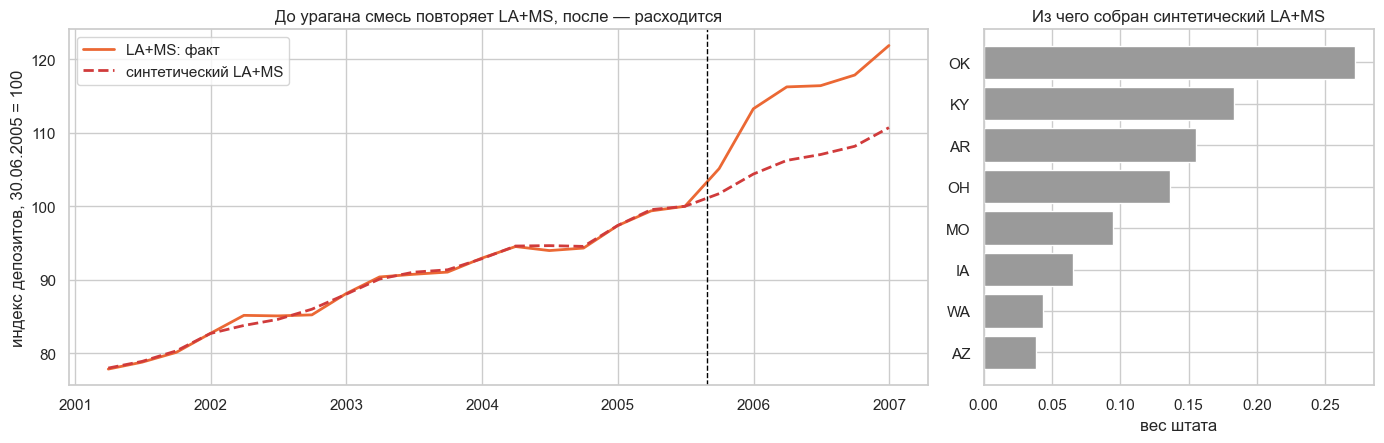

In [33]:
# @title Рисунок: LA+MS и синтетический LA+MS
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax = axes[0]
ax.plot(by_state.index, by_state["LA+MS"], color=TREATED_COLOR, lw=2, label="LA+MS: факт")
ax.plot(by_state.index, synthetic, color=HIDDEN_COLOR, lw=2, ls="--", label="синтетический LA+MS")
ax.axvline(pd.Timestamp("2005-08-29"), color="black", lw=1, ls="--")
ax.set_ylabel("индекс депозитов, 30.06.2005 = 100")
ax.set_title("До урагана смесь повторяет LA+MS, после — расходится")
ax.legend()
shown = weights[weights > 0.01].sort_values()
axes[1].barh(shown.index, shown, color="#9a9a9a")
axes[1].set_xlabel("вес штата")
axes[1].set_title("Из чего собран синтетический LA+MS")
plt.tight_layout()
plt.show()

Синтетический LA+MS на 27 % состоит из Оклахомы, на 18 % — из Кентукки, на 16 % — из Арканзаса, на 14 % — из Огайо, на 9 % — из Миссури, остальное понемногу из других штатов. До урагана он повторяет путь LA+MS с ошибкой 0.45 пункта (RMSPE, root mean squared prediction error). После урагана пути расходятся: разрыв +3.4 пункта на 30 сентября 2005 года, +8.9 к декабрю и +11.2 к концу 2006 года, в среднем +8.8. Депозиты банков LA+MS выросли почти на 9 % от уровня середины 2005 года сверх того, что было бы без урагана. Скорее всего, это страховые выплаты и государственная помощь, осевшие на счетах местных банков.

Многие веса нулевые, как коэффициенты lasso в L03: ограничение «веса ≥ 0, сумма = 1» устроено так же. С L03 связана и проверка. У нас 31 донор и только 18 кварталов до урагана, поэтому подгонка может переобучиться. Подберём веса по кварталам до середины 2004 года, а последние четыре квартала до урагана оставим для проверки.

In [34]:
# Подбираем веса только по кварталам до середины 2004 года, последние четыре квартала до урагана — проверка
fit_rows = by_state.index <= "2004-06-30"
check_rows = (by_state.index > "2004-06-30") & before
weights_fit = synthetic_weights("LA+MS", donors, fit_rows)
gap_fit = by_state["LA+MS"] - by_state[donors] @ weights_fit
print(f"ошибка на подгонке: {np.sqrt((gap_fit[fit_rows] ** 2).mean()):.2f}, "
      f"на отложенных кварталах: {np.sqrt((gap_fit[check_rows] ** 2).mean()):.2f} пункта")
print(f"средний разрыв после урагана с этими весами: {gap_fit[~before].mean():+.1f} пункта")

ошибка на подгонке: 0.48, на отложенных кварталах: 0.63 пункта
средний разрыв после урагана с этими весами: +8.8 пункта


Ошибка на отложенных кварталах 0.63 пункта против 0.48 на подгонке: смесь, подобранная без этих кварталов, повторяет и их. Оценка эффекта та же, +8.8. Синтетический контроль не переобучился.

### 4.3 Плацебо

Стандартных ошибок у синтетического контроля нет, вместо них проверка **плацебо** (placebo). Притворимся, что ураган ударил по каждому донору, и построим синтетический контроль для него из остальных доноров. Если разрыв LA+MS не выделяется среди плацебо-разрывов, эффект не найден.

In [35]:
placebo_gaps = {}
for unit in donors:
    pool = donors.copy()
    pool.remove(unit)                                         # донор становится «обработанным»
    w = synthetic_weights(unit, pool, before)
    placebo_gaps[unit] = by_state[unit] - by_state[pool] @ w  # его разрыв с собственной смесью
placebo_gaps = pd.DataFrame(placebo_gaps)

after_means = placebo_gaps[~before].mean()                   # средние разрывы плацебо после урагана
rank = (after_means >= gap[~before].mean()).sum() + 1        # место LA+MS среди всех
print(f"место LA+MS по среднему разрыву после урагана: {rank} из {len(donors) + 1}")
print("самые большие плацебо-разрывы:", after_means.sort_values(ascending=False).head(3).round(1).to_dict())

место LA+MS по среднему разрыву после урагана: 1 из 32
самые большие плацебо-разрывы: {'SD': 7.4, 'WA': 6.1, 'TN': 4.5}


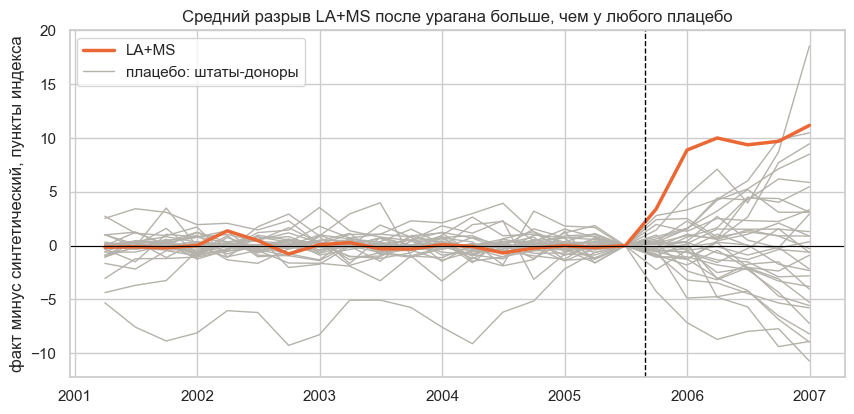

In [36]:
# @title Рисунок: разрывы плацебо и LA+MS
fig, ax = plt.subplots(figsize=(10, 4.5))
for unit in placebo_gaps.columns:
    ax.plot(placebo_gaps.index, placebo_gaps[unit], color="#b4b2aa", lw=1)
ax.plot(gap.index, gap, color=TREATED_COLOR, lw=2.5, label="LA+MS")
ax.plot([], [], color="#b4b2aa", lw=1, label="плацебо: штаты-доноры")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(pd.Timestamp("2005-08-29"), color="black", lw=1, ls="--")
ax.set_ylabel("факт минус синтетический, пункты индекса")
ax.set_title("Средний разрыв LA+MS после урагана больше, чем у любого плацебо")
ax.legend(loc="upper left")
plt.show()

Средний разрыв LA+MS после урагана (+8.8) больше, чем у любого из 31 плацебо-штата; ближайшие — Южная Дакота (+7.4) и Вашингтон (+6.1). Если бы ураган ничего не изменил, LA+MS был бы обычным штатом, и шанс оказаться первым из 32 составил бы 1/32 ≈ 0.03. Это и есть p-значение плацебо-теста.

У нескольких штатов линии далеко от нуля ещё до 2005 года: смесь других штатов их плохо повторяет, и их разрывы после урагана мало что значат. В строгом анализе такие плацебо отбрасывают, место LA+MS от этого стать хуже не может.

## 5. Методы стекаются: PSM + DiD

Простой DiD на «Катрине» не сработал: группа сравнения шла не параллельно. Синтетический контроль починил это на уровне штатов. То же можно сделать на уровне банков, сложив два метода. Сначала сопоставлением подбираем каждому банку LA+MS пять двойников из других штатов по отчёту 30.06.2005, затем на двойниках считаем разность разностей. PSM уравнивает то, что видно перед событием, DiD убирает оставшиеся постоянные различия.

Двойников ищем двумя способами: по шести показателям баланса и по тем же шести плюс рост депозитов за два года до урагана.

In [37]:
# Кандидаты: банки §4 с отчётом на 30.06.2005 и ростом депозитов за два года до урагана
candidates = storm[storm["repdte"] == "2005-06-30"].set_index("cert")
two_years_before = storm[storm["repdte"] == "2003-06-30"].set_index("cert")
candidates["log_assets"] = np.log10(candidates["assets"] * 1000)
candidates["deposit_growth"] = candidates["deposits"] / two_years_before["deposits"] - 1
candidates["gulf"] = (candidates["unit"] == "LA+MS").astype(int)          # 1 — банк LA+MS

SIX = ["log_assets", "c_equity_assets", "l_loans_deposits", "s_securities_assets", "e_roa", "a_npl_gross_loans"]
candidates = candidates.dropna(subset=SIX + ["deposit_growth"])
for feature in SIX + ["deposit_growth"]:                                  # обрезаем хвосты
    low, high = candidates[feature].quantile([0.01, 0.99])
    candidates[feature] = candidates[feature].clip(low, high)

# Индекс депозитов каждого банка по кварталам: строка — банк, столбец — квартал
index_wide = storm.pivot(index="cert", columns="repdte", values="deposit_index")
quarter_before = index_wide.columns <= "2005-06-30"
print("банков LA+MS:", candidates["gulf"].sum(), "| банков других штатов:", (candidates["gulf"] == 0).sum())

банков LA+MS: 46 | банков других штатов: 1218


In [38]:
def matched_did(data, features):
    # Если features пустой — сравниваем со всеми банками других штатов (простой DiD).
    # Иначе: склонность по features -> пять двойников -> разность разностей на двойниках
    is_gulf = data["gulf"].to_numpy() == 1
    if len(features) == 0:
        comparison = data.index[~is_gulf]
    else:
        X = (data[features] - data[features].mean()) / data[features].std()
        ps = LogisticRegression(max_iter=5000).fit(X, data["gulf"]).predict_proba(X)[:, 1]
        ps_logit = np.log(ps / (1 - ps)).reshape(-1, 1)
        neighbors = NearestNeighbors(n_neighbors=K).fit(ps_logit[~is_gulf])
        _, position = neighbors.kneighbors(ps_logit[is_gulf])
        comparison = data.index[~is_gulf][position.ravel()]                # двойники, с повторами
    gulf_path = index_wide.loc[data.index[is_gulf]].mean()                 # средний путь банков LA+MS
    comparison_path = index_wide.loc[comparison].mean()                    # средний путь группы сравнения
    path_gap = gulf_path - comparison_path
    estimate = path_gap[~quarter_before].mean() - path_gap[quarter_before].mean()
    return estimate, gulf_path, comparison_path

SPECS = {"все банки других штатов": [], "двойники по шести показателям": SIX,
         "двойники + рост депозитов": SIX + ["deposit_growth"]}
results = {}
for name, features in SPECS.items():
    estimate, gulf_path, comparison_path = matched_did(candidates, features)
    results[name] = {"оценка": estimate, "LA+MS": gulf_path, "сравнение": comparison_path}
    biggest_before = (gulf_path - comparison_path)[quarter_before].abs().max()   # наибольший разрыв до урагана
    print(f"{name:32s} DiD {estimate:+.1f} пункта | до урагана разрыв до {biggest_before:.1f} пункта")

все банки других штатов          DiD +1.5 пункта | до урагана разрыв до 9.0 пункта
двойники по шести показателям    DiD +5.8 пункта | до урагана разрыв до 5.1 пункта
двойники + рост депозитов        DiD +9.7 пункта | до урагана разрыв до 2.7 пункта


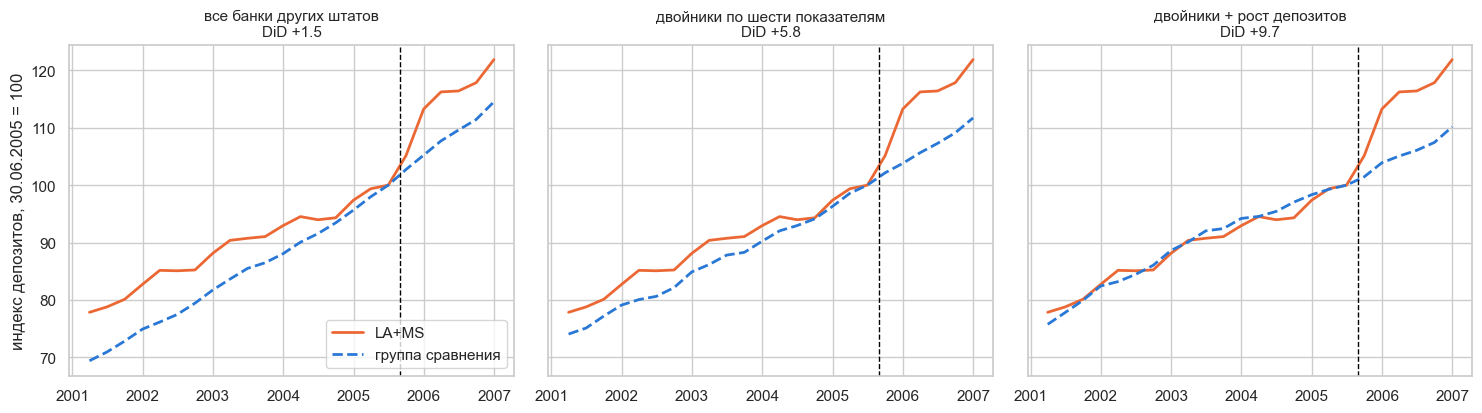

In [39]:
# @title Рисунок: банки LA+MS и три группы сравнения
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, name in zip(axes, SPECS):
    ax.plot(results[name]["LA+MS"].index, results[name]["LA+MS"], color=TREATED_COLOR, lw=2, label="LA+MS")
    ax.plot(results[name]["сравнение"].index, results[name]["сравнение"], color=CONTROL_COLOR, lw=2, ls="--",
            label="группа сравнения")
    ax.axvline(pd.Timestamp("2005-08-29"), color="black", lw=1, ls="--")
    ax.set_title(f"{name}\nDiD {results[name]['оценка']:+.1f}", fontsize=11)
axes[0].set_ylabel("индекс депозитов, 30.06.2005 = 100")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

Банки других штатов росли до урагана быстрее банков LA+MS: разрыв до урагана доходит до 9.0 пункта, и простой DiD даёт +1.5. Двойники по шести показателям похожи на банки LA+MS по размеру, капиталу и структуре баланса, но до урагана всё ещё росли быстрее: разрыв до 5.1 пункта, DiD +5.8. Когда в подбор добавлен рост депозитов, пути до урагана почти совпадают (разрыв не больше 2.7 пункта), а после него разрыв в среднем +9.7.

Точность оценок снова проверим бутстрапом по банкам: в каждой выборке заново подбираем двойников.

In [40]:
rng = np.random.default_rng(SEED)
boot_did = {name: [] for name in SPECS}
for b in range(200):
    rows = rng.integers(0, len(candidates), len(candidates))     # банки с повторами
    sample = candidates.iloc[rows]
    for name, features in SPECS.items():
        boot_did[name].append(matched_did(sample, features)[0])

summary = pd.DataFrame(index=list(SPECS) + ["синтетический контроль (§4)"])
for name in SPECS:
    summary.loc[name, "оценка"] = results[name]["оценка"]
    summary.loc[name, "от"], summary.loc[name, "до"] = np.percentile(boot_did[name], [2.5, 97.5])
summary.loc["синтетический контроль (§4)", "оценка"] = gap[~before].mean()
summary.round(1)

,оценка,от,до
все банки других штатов,1.5,-4.0,6.0
двойники по шести показателям,5.8,-1.6,14.2
двойники + рост депозитов,9.7,4.4,15.2
синтетический контроль (§4),8.8,NaN,NaN


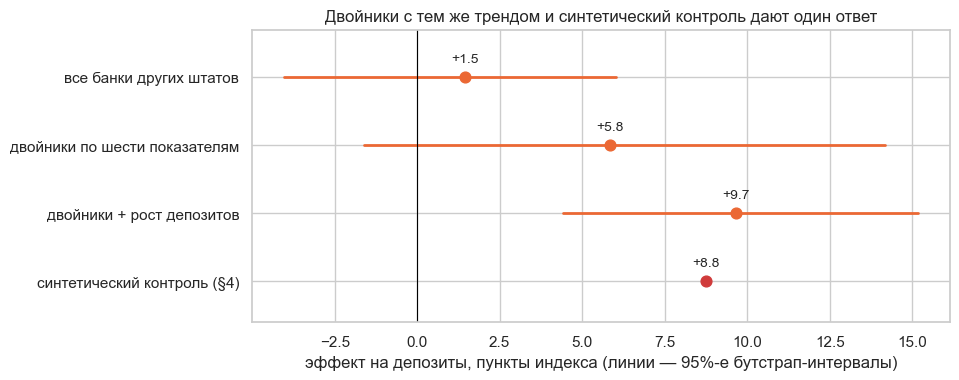

In [41]:
# @title Рисунок: четыре оценки эффекта «Катрины»
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(summary.index)[::-1]
for i, name in enumerate(names):
    row = summary.loc[name]
    color = HIDDEN_COLOR if name.startswith("синтетический") else TREATED_COLOR
    if not np.isnan(row["от"]):
        ax.plot([row["от"], row["до"]], [i, i], color=color, lw=2)
    ax.scatter(row["оценка"], i, color=color, s=60, zorder=3)
    ax.text(row["оценка"], i + 0.22, f"{row['оценка']:+.1f}", ha="center", fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_ylim(-0.6, len(names) - 0.3)
ax.set_xlabel("эффект на депозиты, пункты индекса (линии — 95%-е бутстрап-интервалы)")
ax.set_title("Двойники с тем же трендом и синтетический контроль дают один ответ")
plt.show()

Простой DiD и DiD на двойниках по шести показателям ненадёжны: их интервалы накрывают ноль. Двойники, подобранные ещё и по росту депозитов, дают +9.7 с интервалом от +4.4 до +15.2, а синтетический контроль по штатам дал +8.8. Два разных построения, банки-двойники и смесь штатов, пришли к одному ответу, и это сильнее любого из них по отдельности.

Для DiD важнее всего подобрать группу сравнения с тем же трендом до события. Но здесь есть ловушка. Подбирая по прошлому росту, можно набрать банки, которые случайно отставали или обгоняли, и после события они вернутся к своему обычному темпу (regression to the mean; Daw и Hatfield, 2018). Тогда часть разрыва окажется возвратом к среднему, а эффектом не будет. Проверка — путь двойников на всём отрезке до события, а не только в точках подбора. Рост мы подбирали за 2003–2005 годы, а пути близки с 2001 года.

## Итого

| | Откуда контрфактуал | Что предполагаем о скрытых переменных | Как проверяем |
|---|---|---|---|
| PSM | похожие банки без вмешательства | их нет: всё важное видно | перекрытие, баланс, «спрячь признак» |
| DiD | изменение в контрольной группе | постоянные различия допустимы, тренд должен быть общим | разрывы до события (event study) |
| SC | смесь доноров с весами | допустимы, если смесь повторяет долгую предысторию | подгонка до события, отложенные кварталы, плацебо |
| PSM + DiD | двойники, затем изменения | как в DiD, но тренд общий только у похожих | путь двойников до события |

1. Прогноз отвечает, кто обанкротится, а причинный анализ — что изменится, если вмешаться. Коэффициенты и SHAP прогнозной модели на второй вопрос не отвечают.
2. Эффект — разность факта и контрфактуала. Контрфактуал никогда не наблюдается, его строят из данных, и каждое построение опирается на предпосылку о скрытых переменных.
3. PSM: склонность — логит по видимым признакам, двойники — ближайшие соседи по склонности; проверяем перекрытие и баланс. Брокерские депозиты: наивно +30.7 п.п., после сопоставления +11.8 (от +5.5 до +18.7). Чтобы съесть эффект, скрытая переменная должна быть в 3–4 раза сильнее концентрации в недвижимости.
4. DiD: «после минус до» у обработанных минус то же у контрольных, в регрессии это коэффициент при взаимодействии. Рост ставок 2022 года снизил капитал / активы банков с большой долей бумаг на 3.3 п.п. Регуляторный капитал этого не заметил, а убыток в HTM-бумагах SVB не был виден даже в балансе.
5. SC: смесь доноров повторяет предысторию, разрыв после события — эффект, плацебо — проверка. «Катрина» добавила депозитам банков LA+MS около 9 %.
6. Методы складываются. PSM + DiD на банках и SC на штатах дали один ответ, а совпадение двух независимых построений — сильный аргумент.

## 6. Итоговый проект: как должны выглядеть ноутбук и отчёт

Итоговая работа — небольшое исследование на ваших данных или на данных курса. Образец лежит в папке `пример_итогового_проекта/`: ноутбук `ноутбук.ipynb` и HTML-отчёт `отчёт.html`, который по сохранённому ноутбуку сверстал ИИ-агент. Вопрос образца — связаны ли брокерские депозиты с банкротствами банков. В нём есть описание данных, сравнение групп и одна логистическая модель: проверяем, добавляет ли доля брокерских депозитов информацию к четырём показателям банка. Есть проверка на отложенных банках, интервал для изменения AUC и ограничения. HTML-отчёт оформлен как короткая презентация.

Ноутбук итоговой работы проще лекционного:

- код идёт сверху вниз, без своих функций для рисунков: рисунок — одна-две строки matplotlib или seaborn, с заголовком и подписями осей;
- разделы — как в `итоговый_проект.md`: вопрос и заказчик, данные, протокол валидации, результаты, ограничения;
- каждый результат написан в markdown-ячейке по схеме утверждение → доказательство → неопределённость → ограничение;
- каждое число, которое попадёт в отчёт, напечатано в выводе ячейки;
- ноутбук прогнан сверху вниз и сохранён с выводами.

HTML-отчёт по такому ноутбуку может сверстать агент: промпт и правила — в `итоговый_проект.md`, раздел «HTML-отчёт с помощью агента». Агент только верстает. Текст, числа и выводы ваши, и на защите спрашивать будут вас.